# Figure 2 — cell identity in joint text-based embeddings

This notebook recreates **Figure 2A, 2C, 2D, and 2E**. It loads the held-out HIAI T-cell test dataset and its matching AnnData file, generates fresh embeddings with the six published ablation models and the PubMedBERT baseline, then calculates and displays cell-type-label UMAPs for **Base**, **MD** (literature only), and **MA** (full model). Panel C reproduces the per-cell-type ROC-AUC and synonym balanced-accuracy plots. Panel D shows ALIAS-MA Treg similarities to the canonical label and the curated `FOXP3+ T cell` synonym. Panel E runs the scIB ablation and embedding benchmarks.

The calculations call existing ALIAS embedding, UMAP, annotation, and similarity functions. The notebook selects and displays their saved plots.


## 1. Locate the test inputs

The Figure 2 test data are provided under `out/data/revision1_v1/HIAI_Tcells/S2_heldout_donor_semantic_200k/datasets/HIAI_Tcells/`. The notebook expects `adata_test.h5ad` and the Hugging Face `load_from_disk` directory `scrna_test` there. Set `ALIAS_REVISION_DATA_ROOT` to the parent `revision1_v1` directory if the data are stored elsewhere. Generated embeddings and plots are written to a new, timestamped `analysis_runs/figure2/` folder alongside `datasets/`.


In [5]:
import json
import os
import subprocess
import sys
from dataclasses import asdict
from pathlib import Path

PROJECT_ROOT = next(
    (
        path
        for path in (Path.cwd(), *Path.cwd().parents)
        if (path / "pyproject.toml").is_file() and (path / "src" / "alias").is_dir()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError("Start Jupyter from the ALIAS repository or its notebooks directory.")
sys.path.insert(0, str(PROJECT_ROOT / "src"))
os.environ.setdefault("MPLCONFIGDIR", str(PROJECT_ROOT / ".matplotlib"))

import scanpy as sc
from IPython.display import Markdown, SVG, display

from alias import evaluation as ev
from alias.evaluation.embedding import clean_model_name
from alias.util.artifacts import create_run_directory, write_metadata
from alias.util.saved_dataset import load_saved_dataset

DATASET_ID = "S2_heldout_donor_semantic_200k"
DATA_ROOT = Path(
    os.environ.get("ALIAS_REVISION_DATA_ROOT", PROJECT_ROOT / "out" / "data" / "revision1_v1")
).expanduser().resolve()
DATASET_DIR = DATA_ROOT / "HIAI_Tcells" / DATASET_ID
TEST_INPUT_DIR = DATASET_DIR / "datasets" / "HIAI_Tcells"
SCRNA_TEST_PATH = TEST_INPUT_DIR / "scrna_test"
ADATA_TEST_PATH = TEST_INPUT_DIR / "adata_test.h5ad"
print("Test dataset:", SCRNA_TEST_PATH)
print("Test AnnData:", ADATA_TEST_PATH)

Test dataset: /Users/mariakrissmer/Desktop/Repositories/alias/.worktrees/manuscript-reproducibility/out/data/revision1_v1/HIAI_Tcells/S2_heldout_donor_semantic_200k/datasets/HIAI_Tcells/scrna_test
Test AnnData: /Users/mariakrissmer/Desktop/Repositories/alias/.worktrees/manuscript-reproducibility/out/data/revision1_v1/HIAI_Tcells/S2_heldout_donor_semantic_200k/datasets/HIAI_Tcells/adata_test.h5ad


In [6]:
for path in (SCRNA_TEST_PATH, ADATA_TEST_PATH):
    if not path.exists():
        raise FileNotFoundError(f"Missing Figure 2 test input: {path}")

scrna_test = load_saved_dataset(SCRNA_TEST_PATH)
adata_test = sc.read_h5ad(ADATA_TEST_PATH, backed="r")
required_columns = {"index", "sentence1", "AIFI_L2"}
missing_columns = required_columns - set(scrna_test.column_names)
if missing_columns:
    raise ValueError(f"The test dataset is missing columns: {sorted(missing_columns)}")
dataset_cell_ids = set(map(str, scrna_test["index"]))
adata_cell_ids = set(map(str, adata_test.obs_names))
if len(dataset_cell_ids) != len(scrna_test) or dataset_cell_ids != adata_cell_ids:
    raise ValueError("The cell IDs in scrna_test and adata_test.h5ad do not match.")
print(f"Matched {len(scrna_test):,} test cells; AnnData has {adata_test.n_vars:,} genes.")
print(f"Cell types: {len(set(scrna_test['AIFI_L2']))}")

Matched 100,000 test cells; AnnData has 3,000 genes.
Cell types: 10


## 2. Generate ablation-model embeddings

The model IDs below are the published Hugging Face repositories. `MA*` and `MC*` use `-star` in their repository names. The existing embedding function selects **20,000 cells with seed 42** and encodes the cells, gene names, and cell-type labels for each model. A new analysis run starts with an empty embedding cache. Rerunning the embedding cell reuses matching outputs in that run. To resume after restarting Jupyter, set `ALIAS_FIGURE2_RUN_DIR` to the existing run directory before opening the notebook.

In [7]:
MODEL_IDS = {
    "MA": "mariakrissmer/ALIAS-MA",
    "MA*": "mariakrissmer/ALIAS-MA-star",
    "MB": "mariakrissmer/ALIAS-MB",
    "MC": "mariakrissmer/ALIAS-MC",
    "MC*": "mariakrissmer/ALIAS-MC-star",
    "MD": "mariakrissmer/ALIAS-MD",
    "Base": "neuml/pubmedbert-base-embeddings",
}
PANEL_A_LABELS = ("Base", "MD", "MA")
ANNOTATION_COLUMN = "AIFI_L2"
MAX_CELLS = 20_000
BATCH_SIZE = 256
UMAP_CONFIG = ev.EvaluationConfig(
    n_neighbors=50,
    min_dist=0.2,
    n_components=30,
    random_state=21,
)

figure2_root = (DATASET_DIR / "analysis_runs" / "figure2").resolve()
resume_path = os.environ.get("ALIAS_FIGURE2_RUN_DIR")
if resume_path:
    RUN_DIR = Path(resume_path).expanduser().resolve()
    if not RUN_DIR.is_dir() or RUN_DIR.parent != figure2_root:
        raise ValueError(f"Expected an existing Figure 2 analysis run under {figure2_root}")
else:
    RUN_DIR = create_run_directory(
        root_dir=DATASET_DIR / "analysis_runs",
        category="",
        dataset_name="figure2",
    ).resolve()
git_commit = subprocess.run(
    ["git", "rev-parse", "HEAD"],
    cwd=PROJECT_ROOT,
    check=True,
    capture_output=True,
    text=True,
).stdout.strip()
run_metadata = {
    "notebook": "notebooks/figure2.ipynb",
    "git_commit": git_commit,
    "dataset_id": DATASET_ID,
    "scrna_test_path": str(SCRNA_TEST_PATH),
    "adata_test_path": str(ADATA_TEST_PATH),
    "model_ids": MODEL_IDS,
    "embedding_max_cells": MAX_CELLS,
    "embedding_batch_size": BATCH_SIZE,
    "cell_subsampling_seed": 42,
    "umap_config": asdict(UMAP_CONFIG),
    "panel_a_labels": list(PANEL_A_LABELS),
}
metadata_path = RUN_DIR / "metadata.json"
if resume_path:
    if not metadata_path.is_file() or json.loads(metadata_path.read_text()) != run_metadata:
        raise ValueError(f"The existing Figure 2 run metadata does not match: {metadata_path}")
else:
    write_metadata(RUN_DIR, run_metadata)
print("Analysis run:", RUN_DIR)

Analysis run: /Users/mariakrissmer/Desktop/Repositories/alias/.worktrees/manuscript-reproducibility/out/data/revision1_v1/HIAI_Tcells/S2_heldout_donor_semantic_200k/analysis_runs/figure2/2026-11-10T16-46-36


huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


In [8]:
embeddings = ev.generate_embeddings(
    evaluation_dict={"scrna": {"test": scrna_test}},
    embedding_config=ev.GenEmbeddingsConfig(
        annotation_column=ANNOTATION_COLUMN,
        embedding_models=list(MODEL_IDS.values()),
        model_type="sentence_transformer",
        batch_size=BATCH_SIZE,
        output_dir=str(RUN_DIR / "embeddings"),
        max_cells=MAX_CELLS,
        index=True,
    ),
)
for label, model_id in MODEL_IDS.items():
    model_key = clean_model_name(model_id)
    cell_artifact = embeddings[model_key]["scrna"]["df_cells"]
    print(f"{label:>4}: {cell_artifact['n_samples']:,} cells → {cell_artifact['path']}")

Embedding Models:   0%|          | 0/7 [00:00<?, ?it/s]


 Generating embeddings with model: mariakrissmer/ALIAS-MA
Loading public HuggingFace model 'mariakrissmer/ALIAS-MA'.
Encoding df_cells (20000 samples)


Batches: 100%|██████████| 79/79 [00:54<00:00,  1.44it/s]


Encoding df_genes (2298 samples)


Batches: 100%|██████████| 9/9 [00:00<00:00, 27.12it/s]


Encoding df_celltypes (10 samples)


... (48 outputs left out)

Batches: 100%|██████████| 1/1 [00:00<00:00, 108.82it/s]


Encoding df_labels (10 samples)


Embedding Models: 100%|██████████| 7/7 [07:41<00:00, 65.97s/it]

  MA: 20,000 cells → /Users/mariakrissmer/Desktop/Repositories/alias/.worktrees/manuscript-reproducibility/out/data/revision1_v1/HIAI_Tcells/S2_heldout_donor_semantic_200k/analysis_runs/figure2/2026-11-10T16-46-36/embeddings/scrna/ALIASMA/2026-11-10T16-46-42/df_cells.parquet
 MA*: 20,000 cells → /Users/mariakrissmer/Desktop/Repositories/alias/.worktrees/manuscript-reproducibility/out/data/revision1_v1/HIAI_Tcells/S2_heldout_donor_semantic_200k/analysis_runs/figure2/2026-11-10T16-46-36/embeddings/scrna/ALIASMAstar/2026-11-10T16-47-40/df_cells.parquet
  MB: 20,000 cells → /Users/mariakrissmer/Desktop/Repositories/alias/.worktrees/manuscript-reproducibility/out/data/revision1_v1/HIAI_Tcells/S2_heldout_donor_semantic_200k/analysis_runs/figure2/2026-11-10T16-46-36/embeddings/scrna/ALIASMB/2026-11-10T16-48-39/df_cells.parquet
  MC: 20,000 cells → /Users/mariakrissmer/Desktop/Repositories/alias/.worktrees/manuscript-reproducibility/out/data/revision1_v1/HIAI_Tcells/S2_heldout_donor_semantic_2

## 3. Calculate Figure 2A UMAPs

The plotting function receives only the three Figure 2A models. It computes PCA followed by a joint UMAP of cell and cell-type-label embeddings, and saves both the coordinates and SVG plots. These settings match the existing ALIAS-MA cell-type-label UMAP: **30 PCA components, 50 neighbors, minimum distance 0.2, and seed 21**. The other ablation embeddings remain available in `embeddings` for later panels.

In [9]:
panel_a_embeddings = {
    clean_model_name(MODEL_IDS[label]): embeddings[clean_model_name(MODEL_IDS[label])]
    for label in PANEL_A_LABELS
}
PANEL_A_PLOT_ROOT = RUN_DIR / "plots" / "figure2a"
panel_a_embeddings = ev.umap_plots(
    embeddings_dict=panel_a_embeddings,
    annotation_column=ANNOTATION_COLUMN,
    output_dir=str(PANEL_A_PLOT_ROOT),
    evaluation_config=UMAP_CONFIG,
)

Evaluating model: pubmedbertbaseembeddings
Processing dataset: scrna
Computing UMAP for 20010 embeddings...


/Users/mariakrissmer/Desktop/Repositories/alias/.venv_alias/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/mariakrissmer/Desktop/Repositories/alias/.venv_alias/lib/python3.12/site-packages/pandas/io/parquet.py:191: UserWarning: The DataFrame has column names of mixed type. They will be converted to strings and not roundtrip correctly.
  table = self.api.Table.from_pandas(df, **from_pandas_kwargs)


✅ Saved UMAP coords and plots for pubmedbertbaseembeddings / scrna

Evaluating model: ALIASMD
Processing dataset: scrna
Computing UMAP for 20010 embeddings...


/Users/mariakrissmer/Desktop/Repositories/alias/.venv_alias/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/mariakrissmer/Desktop/Repositories/alias/.venv_alias/lib/python3.12/site-packages/pandas/io/parquet.py:191: UserWarning: The DataFrame has column names of mixed type. They will be converted to strings and not roundtrip correctly.
  table = self.api.Table.from_pandas(df, **from_pandas_kwargs)


✅ Saved UMAP coords and plots for ALIASMD / scrna

Evaluating model: ALIASMA
Processing dataset: scrna
Computing UMAP for 20010 embeddings...


/Users/mariakrissmer/Desktop/Repositories/alias/.venv_alias/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/mariakrissmer/Desktop/Repositories/alias/.venv_alias/lib/python3.12/site-packages/pandas/io/parquet.py:191: UserWarning: The DataFrame has column names of mixed type. They will be converted to strings and not roundtrip correctly.
  table = self.api.Table.from_pandas(df, **from_pandas_kwargs)


✅ Saved UMAP coords and plots for ALIASMA / scrna



## 4. View the Figure 2A panels

The display helper reads the exact SVG created by `umap_plots` for each model. It does not repeat the UMAP or plotting calculations.

### Base — PubMedBERT before ALIAS fine-tuning

Saved plot: plots/figure2a/pubmedbertbaseembeddings/scrna/celltype_label_plots/2026-11-10T16-53-10/cells_with_celltype_labels.svg


### MD — literature-only training

Saved plot: plots/figure2a/ALIASMD/scrna/celltype_label_plots/2026-11-10T16-51-52/cells_with_celltype_labels.svg


### MA — joint cell and literature training

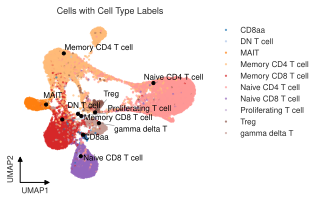

Saved plot: plots/figure2a/ALIASMA/scrna/celltype_label_plots/2026-11-10T16-46-42/cells_with_celltype_labels.svg


In [10]:
def show_celltype_umap(label: str, description: str) -> None:
    model_key = clean_model_name(MODEL_IDS[label])
    umap_artifact = panel_a_embeddings[model_key]["scrna"]["df_cells"]["umap"]
    figure_run = Path(umap_artifact["path"]).parent.name
    plot_path = (
        PANEL_A_PLOT_ROOT
        / model_key
        / "scrna"
        / "celltype_label_plots"
        / figure_run
        / "cells_with_celltype_labels.svg"
    )
    if not plot_path.is_file():
        raise FileNotFoundError(f"Missing saved UMAP plot: {plot_path}")
    display(Markdown(f"### {label} — {description}"))
    display(SVG(filename=str(plot_path)))
    print("Saved plot:", plot_path.relative_to(RUN_DIR))

for label, description in (
    ("Base", "PubMedBERT before ALIAS fine-tuning"),
    ("MD", "literature-only training"),
    ("MA", "joint cell and literature training"),
):
    show_celltype_umap(label, description)

## 5. Figure 2C

The first plot uses each model's saved cell and canonical cell-type-label embeddings to calculate annotation predictions, per-cell-type ROC-AUC, and the publication boxplot. The second plot uses the curated synonym mapping in `reproducibility/inputs/hiai_tcells/synonym_mapping.csv`. It encodes **only the additional synonym labels** and reuses the same cell embeddings. Its original-annotation bars come from the normal annotation metrics generated in this step.

The evaluation runs in a new timestamped folder inside `RUN_DIR/figure2c/`. Its embedding manifest records the exact files and public Hugging Face model IDs. Existing evaluation and plotting functions do the calculations; the notebook only supplies paths and selects the two publication plots.


In [11]:
from alias.util.plots.color_definition import (
    PUBLICATION_ABLATION_MODEL_LABELS,
    PUBLICATION_ABLATION_MODEL_ORDER,
)

model_sources = {
    internal_id: MODEL_IDS[PUBLICATION_ABLATION_MODEL_LABELS[internal_id]]
    for internal_id in PUBLICATION_ABLATION_MODEL_ORDER
}
PANEL_C_RUN_DIR = create_run_directory(
    root_dir=RUN_DIR,
    category="figure2c",
    dataset_name="annotation",
).resolve()
manifest_path = PANEL_C_RUN_DIR / "embedding_manifest.json"
manifest = {
    "dataset_id": DATASET_ID,
    "analysis_run": str(RUN_DIR.resolve()),
    "git_commit": git_commit,
    "scrna_test_path": str(SCRNA_TEST_PATH),
    "adata_test_path": str(ADATA_TEST_PATH),
    "model_sources": model_sources,
    "observed_labels": sorted(set(map(str, scrna_test[ANNOTATION_COLUMN]))),
    "embeddings": embeddings,
}
manifest_path.write_text(json.dumps(manifest, indent=2, sort_keys=True), encoding="utf-8")

figure2c_env = os.environ.copy()
figure2c_env.update({
    "ALIAS_REVISION_DATA_ROOT": str(DATA_ROOT),
    "HIAI_TCELLS_SCRNA_TEST_PATH": str(SCRNA_TEST_PATH),
    "HIAI_TCELLS_ADATA_TEST_PATH": str(ADATA_TEST_PATH),
    "HIAI_TCELLS_ANNOTATION_OUTPUT_DIR": str(PANEL_C_RUN_DIR / "celltype_annotation"),
    "HIAI_TCELLS_SYNONYM_OUTPUT_DIR": str(PANEL_C_RUN_DIR / "celltype_annotation_synonym"),
    "HIAI_TCELLS_EMBEDDING_ROOT": str(RUN_DIR / "embeddings"),
    "PYTHONPATH": str(PROJECT_ROOT / "src") + (
        os.pathsep + os.environ["PYTHONPATH"] if os.environ.get("PYTHONPATH") else ""
    ),
})
runner = (
    PROJECT_ROOT
    / "scripts" / "revision1_v1" / "HIAI_Tcells"
    / "celltype_annotation" / "run_celltype_annotation.py"
)
subprocess.run(
    [
        sys.executable,
        str(runner),
        "--models", ",".join(PUBLICATION_ABLATION_MODEL_ORDER),
        "--figure2c-embeddings", str(manifest_path),
    ],
    cwd=PROJECT_ROOT,
    env=figure2c_env,
    check=True,
)
print("Figure 2C evaluation run:", PANEL_C_RUN_DIR)


huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


Running annotation benchmark for Base
Evaluating model: pubmedbertbaseembeddings
Processing dataset: scrna


1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
1 extra bytes in post.stringData array
'created' timestamp seems very low

Running annotation benchmark for MI
Evaluating model: ALIASMD
Processing dataset: scrna


1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
1 extra bytes in post.stringData array
'created' timestamp seems very low

Running annotation benchmark for MF
Evaluating model: ALIASMC
Processing dataset: scrna


... (20 outputs left out)

Batches: 100%|██████████| 1/1 [00:00<00:00, 36.72it/s]


Loading public HuggingFace model 'mariakrissmer/ALIAS-MC-star'.


Batches: 100%|██████████| 1/1 [00:00<00:00, 14.74it/s]


Figure 2C evaluation run: /Users/mariakrissmer/Desktop/Repositories/alias/.worktrees/manuscript-reproducibility/out/data/revision1_v1/HIAI_Tcells/S2_heldout_donor_semantic_200k/analysis_runs/figure2/2026-11-10T16-46-36/figure2c/annotation/2026-11-10T16-55-05


## 6. View the Figure 2C plots

The exact publication PDF filenames are saved in the new evaluation run. Their companion PNGs are displayed here so both plots appear inline in Jupyter.


### ROC-AUC per cell type

Each point is one cell type; boxes summarize performance across the seven models.

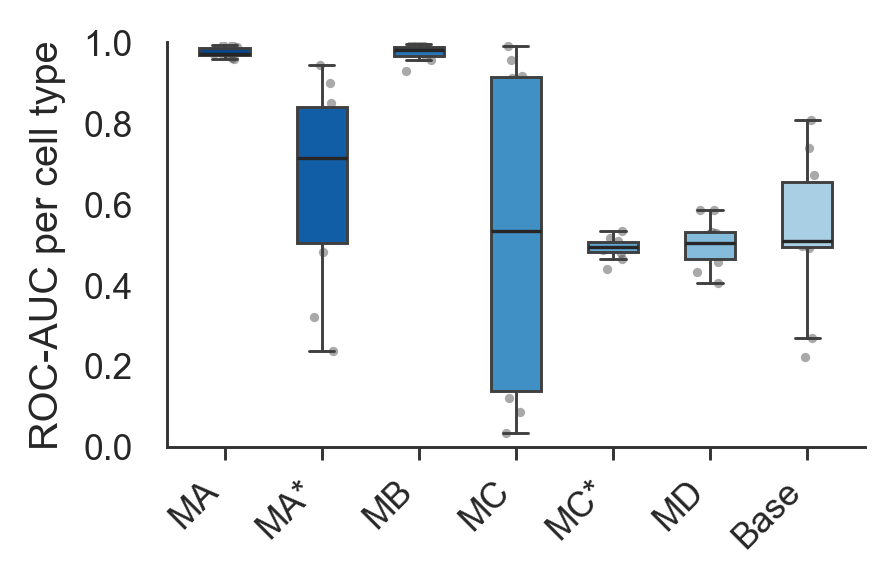

Publication PDF: figure2c/annotation/2026-11-10T16-55-05/celltype_annotation/plots/ablation_annotation_effect/roc_auc_per_celltype_boxplot.pdf


### Balanced accuracy with synonyms

Original cell-type names are compared with the curated synonym variants.

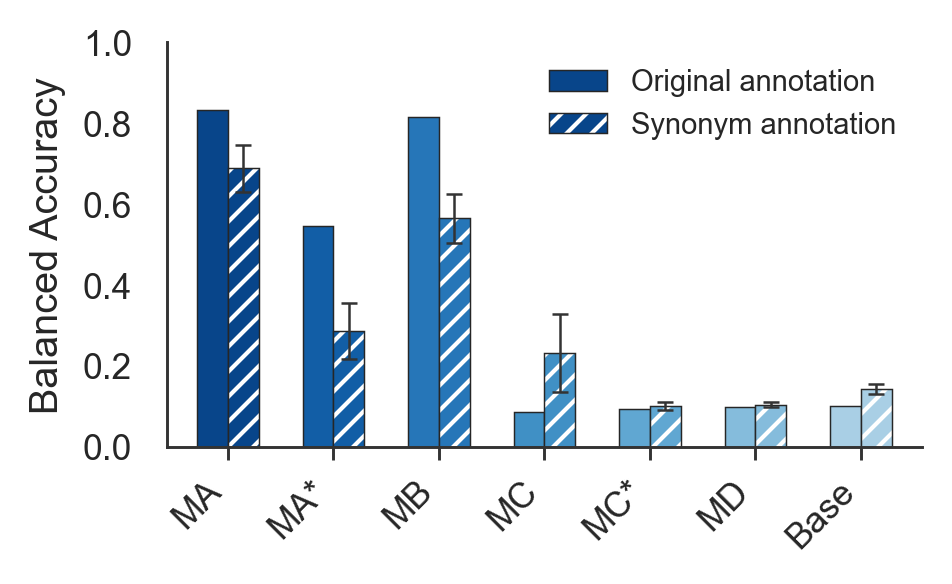

Publication PDF: figure2c/annotation/2026-11-10T16-55-05/celltype_annotation_synonym/balanced_accuracy_original_vs_synonym_annotations.pdf


In [12]:
from IPython.display import Image

roc_auc_pdf = (
    PANEL_C_RUN_DIR / "celltype_annotation" / "plots"
    / "ablation_annotation_effect" / "roc_auc_per_celltype_boxplot.pdf"
)
synonym_pdf = (
    PANEL_C_RUN_DIR / "celltype_annotation_synonym"
    / "balanced_accuracy_original_vs_synonym_annotations.pdf"
)

def show_saved_plot(title: str, explanation: str, pdf_path: Path) -> None:
    png_path = pdf_path.with_suffix(".png")
    for path in (pdf_path, png_path):
        if not path.is_file():
            raise FileNotFoundError(f"Missing saved publication plot: {path}")
    display(Markdown(f"### {title}\n\n{explanation}"))
    display(Image(filename=str(png_path)))
    print("Publication PDF:", pdf_path.relative_to(RUN_DIR))

show_saved_plot(
    "ROC-AUC per cell type",
    "Each point is one cell type; boxes summarize performance across the seven models.",
    roc_auc_pdf,
)
show_saved_plot(
    "Balanced accuracy with synonyms",
    "Original cell-type names are compared with the curated synonym variants.",
    synonym_pdf,
)


## 7. Figure 2D

Panel D compares **ALIAS-MA** cell embeddings with the canonical **Treg** label and the curated **FOXP3+ T cell** synonym. The Treg ROC curve, histogram, and similarity UMAP come from the canonical label evaluation in Panel C. The synonym comparison calls the same similarity evaluator and reuses the cell embeddings and UMAP coordinates calculated above. It also reuses the synonym text embeddings produced for Panel C when their metadata matches. The synonym plots and metadata are saved in a separate timestamped folder inside this Figure 2 analysis run.


In [18]:
PANEL_D_RUN_DIR = create_run_directory(
    root_dir=RUN_DIR,
    category="figure2d",
    dataset_name="treg_label_similarity",
).resolve()
figure2d_env = figure2c_env.copy()
figure2d_env["HIAI_TCELLS_SYNONYM_OUTPUT_DIR"] = str(
    PANEL_D_RUN_DIR / "synonym_label_similarity"
)
subprocess.run(
    [
        sys.executable,
        str(runner),
        "--models", "MB",
        "--figure2d-embeddings", str(manifest_path),
    ],
    cwd=PROJECT_ROOT,
    env=figure2d_env,
    check=True,
)
print("Figure 2D synonym results:", PANEL_D_RUN_DIR.relative_to(RUN_DIR))


huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


Loaded synonym mapping from /Users/mariakrissmer/Desktop/Repositories/alias/.worktrees/manuscript-reproducibility/reproducibility/inputs/hiai_tcells/synonym_mapping.csv


1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


Figure 2D synonym results: figure2d/treg_label_similarity/2026-11-10T18-30-41


## 8. View the Figure 2D plots

Each comparison has a similarity UMAP, ROC curve, and score histogram. The notebook displays PNG previews converted from the saved publication PDFs. This preview step requires `pdftoppm` (Poppler); the scientific plots themselves are already saved by the ALIAS evaluator.


huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


### Treg : Treg — Similarity UMAP

Similarity to the canonical Treg label.

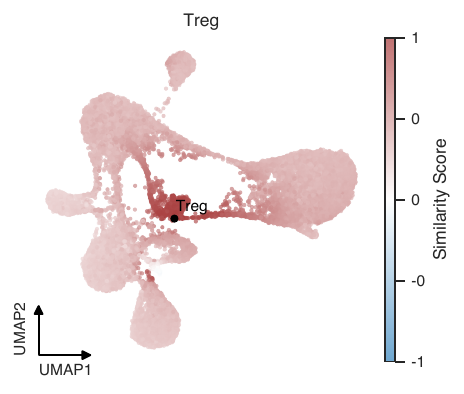

Publication PDF: figure2c/annotation/2026-11-10T16-55-05/celltype_annotation/MB/label_similarity/ALIASMA/scrna/celltype_label_similarity/2026-11-10T16-46-42/umap/Treg_umap.pdf


huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


### Treg : Treg — ROC curve

Similarity to the canonical Treg label.

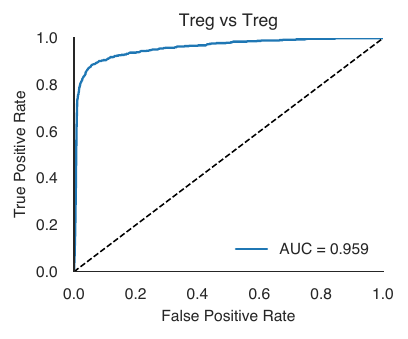

Publication PDF: figure2c/annotation/2026-11-10T16-55-05/celltype_annotation/MB/label_similarity/ALIASMA/scrna/celltype_label_similarity/2026-11-10T16-46-42/roc_curves/Treg_Treg_roc.pdf


huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


### Treg : Treg — Similarity histogram

Similarity to the canonical Treg label.

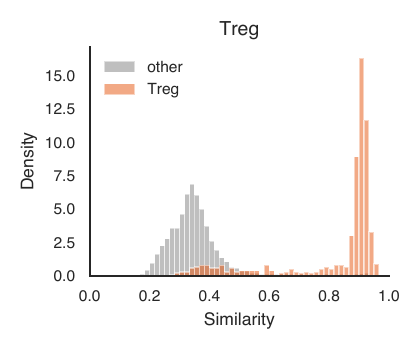

Publication PDF: figure2c/annotation/2026-11-10T16-55-05/celltype_annotation/MB/label_similarity/ALIASMA/scrna/celltype_label_similarity/2026-11-10T16-46-42/histograms/Treg_Treg_hist.pdf


huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


### Treg : FOXP3+ T cell — Similarity UMAP

Similarity to the curated Treg synonym.

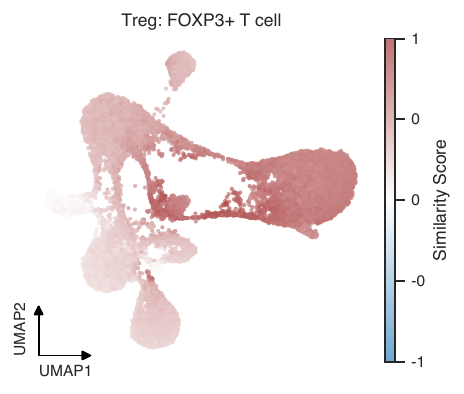

Publication PDF: figure2d/treg_label_similarity/2026-11-10T16-55-57/synonym_label_similarity/Treg__FOXP3_T_cell/umap/Treg: FOXP3+ T cell_umap.pdf


huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


### Treg : FOXP3+ T cell — ROC curve

Similarity to the curated Treg synonym.

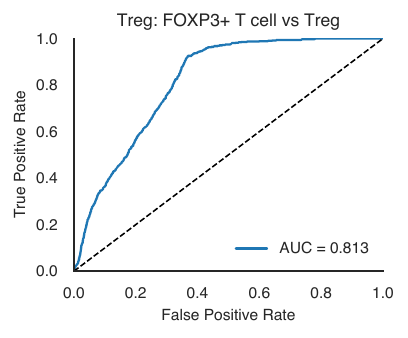

Publication PDF: figure2d/treg_label_similarity/2026-11-10T16-55-57/synonym_label_similarity/Treg__FOXP3_T_cell/roc_curves/Treg__FOXP3__T_cell_Treg_roc.pdf


huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


### Treg : FOXP3+ T cell — Similarity histogram

Similarity to the curated Treg synonym.

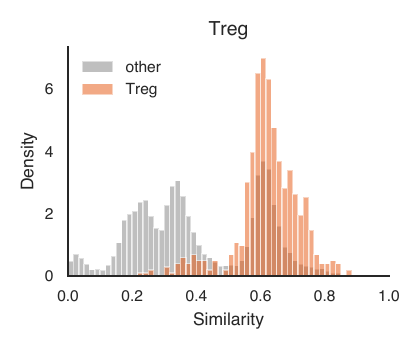

Publication PDF: figure2d/treg_label_similarity/2026-11-10T16-55-57/synonym_label_similarity/Treg__FOXP3_T_cell/histograms/Treg__FOXP3__T_cell_Treg_hist.pdf


In [15]:
import shutil

canonical_rocs = list(
    (PANEL_C_RUN_DIR / "celltype_annotation" / "MB" / "label_similarity").glob(
        "*/scrna/celltype_label_similarity/*/roc_curves/Treg_Treg_roc.pdf"
    )
)
if len(canonical_rocs) != 1:
    raise FileNotFoundError(
        f"Expected one canonical Treg evaluation from Panel C; found {len(canonical_rocs)}."
    )
canonical_eval_dir = canonical_rocs[0].parent.parent
synonym_eval_dir = (
    PANEL_D_RUN_DIR / "synonym_label_similarity" / "Treg__FOXP3_T_cell"
)

def unique_pdf(directory: Path, pattern: str) -> Path:
    matches = list(directory.glob(pattern))
    if len(matches) != 1:
        raise FileNotFoundError(
            f"Expected one PDF matching {pattern!r} in {directory}; found {len(matches)}."
        )
    return matches[0]

def show_saved_similarity_pdf(title: str, explanation: str, pdf_path: Path) -> None:
    converter = shutil.which("pdftoppm")
    if converter is None:
        raise RuntimeError("Install Poppler's pdftoppm to display the saved PDF plots.")
    preview_path = pdf_path.with_suffix(".png")
    if not preview_path.exists() or preview_path.stat().st_mtime < pdf_path.stat().st_mtime:
        subprocess.run(
            [converter, "-f", "1", "-singlefile", "-r", "140", "-png",
             str(pdf_path), str(preview_path.with_suffix(""))],
            check=True,
        )
    display(Markdown(f"### {title}\n\n{explanation}"))
    display(Image(filename=str(preview_path)))
    print("Publication PDF:", pdf_path.relative_to(RUN_DIR))

for label, explanation, evaluation_dir, plots in (
    (
        "Treg : Treg",
        "Similarity to the canonical Treg label.",
        canonical_eval_dir,
        (
            ("Similarity UMAP", "umap", "Treg_umap.pdf"),
            ("ROC curve", "roc_curves", "Treg_Treg_roc.pdf"),
            ("Similarity histogram", "histograms", "Treg_Treg_hist.pdf"),
        ),
    ),
    (
        "Treg : FOXP3+ T cell",
        "Similarity to the curated Treg synonym.",
        synonym_eval_dir,
        (
            ("Similarity UMAP", "umap", "Treg: FOXP3+ T cell_umap.pdf"),
            ("ROC curve", "roc_curves", "Treg__FOXP3__T_cell_Treg_roc.pdf"),
            ("Similarity histogram", "histograms", "Treg__FOXP3__T_cell_Treg_hist.pdf"),
        ),
    ),
):
    for plot_type, folder, filename in plots:
        show_saved_similarity_pdf(
            f"{label} — {plot_type}",
            explanation,
            unique_pdf(evaluation_dir / folder, filename),
        )


## 9. Figure 2E

The scIB runner computes the ablation embedding assessment and the embedding benchmark using the same 20,000 held-out cells sampled above. It takes the seven newly generated ALIAS/PubMedBERT cell embeddings from this Figure 2 run and calculates the three PCA baselines from `scrna_test` and `adata_test.h5ad`. The scGPT and two scVI embeddings are versioned benchmark inputs saved in `out/data/revision1_v1/HIAI_Tcells/S2_heldout_donor_semantic_200k/embeddings_evaluation/external_embeddings/`; their available model files are in `out/models/`. The dataset-adapted scVI embedding has no saved adapted checkpoint, so its deposited embedding file is the exact input for that comparison. The runner aligns every embedding by cell ID and saves fresh scIB scores and plots in a new timestamped Panel E folder. It does not read scIB scores from earlier runs.

The scIB calculation can take substantial time. Set `ALIAS_FIGURE2_SCIB_PYTHON` to a Python interpreter with `scib_metrics` installed if the automatically selected `.venv_annotation` environment is unavailable.


In [16]:
EXTERNAL_EMBEDDINGS_DIR = DATASET_DIR / "embeddings_evaluation" / "external_embeddings"
for filename in (
    "scGPT.parquet",
    "scVI_census_pretrained.parquet",
    "scVI_census_dataset_adapted.parquet",
):
    path = EXTERNAL_EMBEDDINGS_DIR / filename
    if not path.is_file():
        raise FileNotFoundError(f"Missing versioned Figure 2E benchmark input: {path}")

configured_python = os.environ.get("ALIAS_FIGURE2_SCIB_PYTHON")
if configured_python:
    SCIB_PYTHON = Path(configured_python).expanduser().resolve()
else:
    common_dir_text = subprocess.run(
        ["git", "rev-parse", "--git-common-dir"],
        cwd=PROJECT_ROOT,
        check=True,
        capture_output=True,
        text=True,
    ).stdout.strip()
    common_git_dir = (PROJECT_ROOT / common_dir_text).resolve()
    main_checkout = common_git_dir.parent
    candidate = main_checkout / ".venv_annotation" / "bin" / "python"
    SCIB_PYTHON = candidate if candidate.is_file() else Path(sys.executable)
if not SCIB_PYTHON.is_file():
    raise FileNotFoundError(f"Figure 2E Python interpreter does not exist: {SCIB_PYTHON}")

PANEL_E_RUN_DIR = create_run_directory(
    root_dir=RUN_DIR,
    category="figure2e",
    dataset_name="scib_embedding_comparison",
).resolve()
figure2e_env = figure2c_env.copy()
figure2e_env.pop("HIAI_TCELLS_SCIB_MODELS", None)
figure2e_env.update({
    "HIAI_TCELLS_SCIB_OUTPUT_DIR": str(PANEL_E_RUN_DIR),
    "HIAI_TCELLS_SCIB_EXTERNAL_EMBEDDING_DIR": str(EXTERNAL_EMBEDDINGS_DIR),
    "HIAI_TCELLS_SCIB_EMBEDDING_MANIFEST": str(manifest_path),
    "HIAI_TCELLS_SCIB_REQUIRE_CACHED_EMBEDDINGS": "1",
    "HIAI_TCELLS_SCIB_MAX_CELLS": str(MAX_CELLS),
    "HIAI_TCELLS_SCIB_BATCH_SIZE": str(BATCH_SIZE),
})
scib_runner = (
    PROJECT_ROOT / "scripts" / "revision1_v1" / "HIAI_Tcells"
    / "embeddings_evaluation" / "eval_embedding_comparison.py"
)
subprocess.run(
    [str(SCIB_PYTHON), str(scib_runner)],
    cwd=PROJECT_ROOT,
    env=figure2e_env,
    check=True,
)
print("Figure 2E results:", PANEL_E_RUN_DIR.relative_to(RUN_DIR))


huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


Dependency guidance for .venv_annotation:
  uv pip install --python .venv_annotation/bin/python "scib-metrics>=0.5.0"
  uv pip install --python .venv_annotation/bin/python "scikit-learn>=1.4" "pyarrow>=15"
Optional only if future scripts generate external embeddings instead of loading files:
  uv pip install --python .venv_annotation/bin/python "scvi-tools>=1.2"
  uv pip install --python .venv_annotation/bin/python "scgpt"
Could not load local scrna_test from /Users/mariakrissmer/Desktop/Repositories/alias/.worktrees/manuscript-reproducibility/out/data/revision1_v1/HIAI_Tcells/S2_heldout_donor_semantic_200k/datasets/HIAI_Tcells/scrna_test: TypeError: must be called with a dataclass type or instance
Reading local scrna_test Arrow files directly instead.
Using adata.obs['batch_id'] as scIB batch column 'batch'
Preparing embedding for Base (sentence_transformer)
Reusing Figure 2 Base cell embeddings from /Users/mariakrissmer/Desktop/Repositories/alias/.worktrees/manuscript-reproducibility

/Users/mariakrissmer/Desktop/Repositories/alias/.venv_annotation/lib/python3.12/site-packages/scanpy/preprocessing/_pca/__init__.py:226: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  mask_var_param, mask_var = _handle_mask_var(
Embeddings:   8%|▊         | 1/13 [01:21<16:16, 81.38s/it]tch correction: pcr_comparison]
                                                                                         
Embeddings:  15%|█▌        | 2/13 [02:36<14:13, 77.55s/it]tch correction: pcr_comparison]
                                                                                         
Embeddings:  23%|██▎       | 3/13 [03:51<12:43, 76.35s/it]tch correction: pcr_comparison]
                                                                                         
Embeddings:  31%|███       | 4/13 [05:06<11:

Saved scIB embedding comparison outputs to /Users/mariakrissmer/Desktop/Repositories/alias/.worktrees/manuscript-reproducibility/out/data/revision1_v1/HIAI_Tcells/S2_heldout_donor_semantic_200k/analysis_runs/figure2/2026-11-10T16-46-36/figure2e/scib_embedding_comparison/2026-11-10T17-03-33
Figure 2E results: figure2e/scib_embedding_comparison/2026-11-10T17-03-33


## 10. View the Figure 2E plots

The first PDF summarizes scIB batch correction, biological conservation, and total scores across the ablation models. The second PDF compares total scIB scores for ALIAS and the PCA, scGPT, and scVI benchmarks. Their PNG companions are displayed below.


### Ablation embedding assessment

scIB scores for the six ALIAS ablations and PubMedBERT Base.

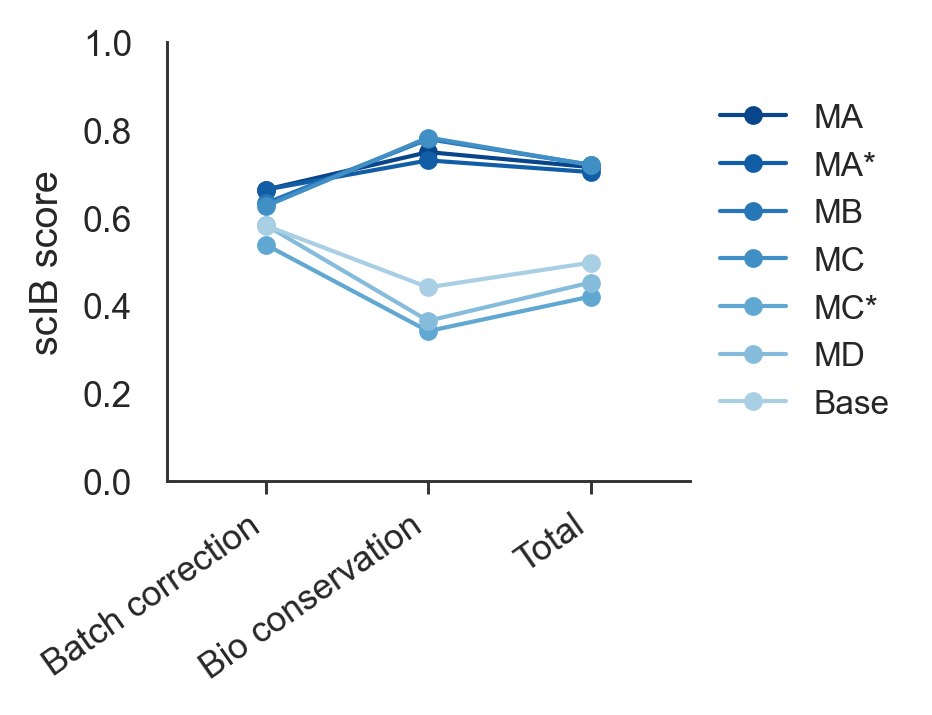

Publication PDF: figure2e/scib_embedding_comparison/2026-11-10T17-03-33/ablation_scib_scores_by_score.pdf


### Embedding benchmark

Total scIB score compared with the PCA, scGPT, and scVI baselines.

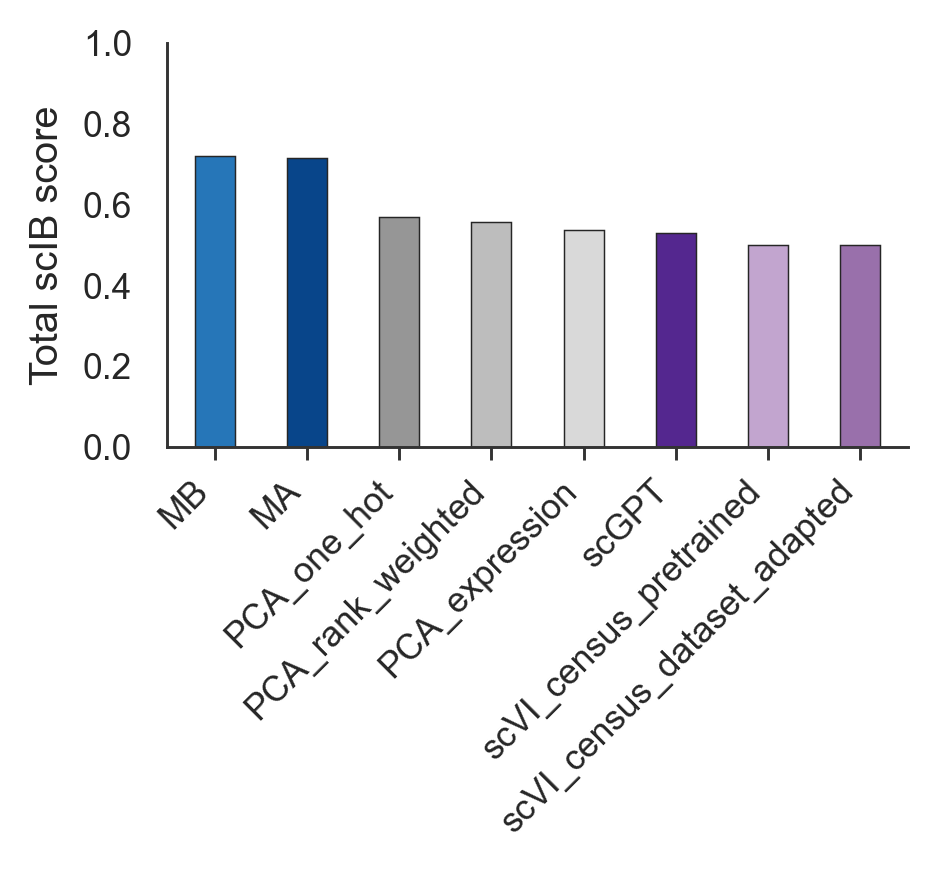

Publication PDF: figure2e/scib_embedding_comparison/2026-11-10T17-03-33/benchmark_total_scib_score.pdf


In [17]:
show_saved_plot(
    "Ablation embedding assessment",
    "scIB scores for the six ALIAS ablations and PubMedBERT Base.",
    PANEL_E_RUN_DIR / "ablation_scib_scores_by_score.pdf",
)
show_saved_plot(
    "Embedding benchmark",
    "Total scIB score compared with the PCA, scGPT, and scVI baselines.",
    PANEL_E_RUN_DIR / "benchmark_total_scib_score.pdf",
)
